#### Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from scipy.sparse import load_npz

from sklearn.linear_model import RidgeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.utils.validation import check_is_fitted

# Configuring display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


#### Loading the Processed Datasets and Feature Matrices

In [2]:
# Defining data directories
processed_dir = Path("../data/processed")
features_dir = processed_dir / "features"

# Loading processed datasets
train_df = pd.read_csv(processed_dir / "train.csv")
test_df = pd.read_csv(processed_dir / "test.csv")

# Loading encoded target variables
y_train = np.load(features_dir / "y_train.npy")
y_test = np.load(features_dir / "y_test.npy")

# Identifying saved Character TF-IDF feature matrices
print("Available feature matrices:")

for file in sorted(features_dir.glob("*.npz")):
    print(f" - {file.name}")

print("\nProcessed Dataset Shapes:")
print(f"Training dataset: {train_df.shape}")
print(f"Test dataset: {test_df.shape}")

print("\nTarget Shapes:")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

Available feature matrices:
 - X_test_char.npz
 - X_test_combined.npz
 - X_test_word.npz
 - X_train_char.npz
 - X_train_combined.npz
 - X_train_word.npz

Processed Dataset Shapes:
Training dataset: (28919, 8)
Test dataset: (6391, 8)

Target Shapes:
y_train: (28919,)
y_test: (6391,)


**Observations on Dataset Loading:**

- The processed training and test datasets contain **28,919** and **6,391 records**, respectively.
- Both datasets have corresponding encoded target arrays with matching sample counts, confirming consistent data alignment.
- Word-level, character-level, and combined TF-IDF feature matrices are available. **Character TF-IDF** will be used for evaluating the selected Ridge Classifier.

#### Loading Character TF-IDF Feature Matrices

In [3]:
# Loading saved Character TF-IDF matrices
X_train_char = load_npz(
    features_dir / "X_train_char.npz"
)

X_test_char = load_npz(
    features_dir / "X_test_char.npz"
)

# Validating feature dimensions
assert X_train_char.shape[0] == len(y_train)
assert X_test_char.shape[0] == len(y_test)

assert X_train_char.shape[1] == X_test_char.shape[1]

# Displaying feature matrix information
print("Character TF-IDF Feature Matrices")
print("-" * 45)

print(f"Training features: {X_train_char.shape}")
print(f"Test features: {X_test_char.shape}")

print(f"\nTraining matrix type: {type(X_train_char).__name__}")
print(f"Test matrix type: {type(X_test_char).__name__}")

print(f"\nNumber of features: {X_train_char.shape[1]:,}")

print("\nFeature matrices loaded and validated successfully.")

Character TF-IDF Feature Matrices
---------------------------------------------
Training features: (28919, 50000)
Test features: (6391, 50000)

Training matrix type: csr_matrix
Test matrix type: csr_matrix

Number of features: 50,000

Feature matrices loaded and validated successfully.


**Observations on Character TF-IDF Feature Matrices:**

- The training and test matrices contain **28,919** and **6,391 samples**, respectively, represented using **50,000 character-level TF-IDF features**.
- Both matrices use the **CSR sparse format**, enabling memory-efficient storage and computation with high-dimensional text features.
- Feature dimensions and target alignment were successfully validated, confirming that the datasets are ready for model evaluation.

#### Reconstructing the Selected Ridge Classifier

In [4]:
# Initializing the selected model
final_model = RidgeClassifier(
    alpha=0.5
)

# Fitting the model on the complete training dataset
final_model.fit(
    X_train_char,
    y_train
)

# Verifying fitted model status
check_is_fitted(final_model)

# Displaying model information
print("Final Model Reconstruction")
print("-" * 45)

print(f"Model: {type(final_model).__name__}")
print(f"Alpha: {final_model.alpha}")
print(f"Training Samples: {X_train_char.shape[0]:,}")
print(f"Number of Features: {X_train_char.shape[1]:,}")
print(f"Number of Classes: {len(final_model.classes_)}")

print("\nFinal Ridge Classifier reconstructed successfully.")

Final Model Reconstruction
---------------------------------------------
Model: RidgeClassifier
Alpha: 0.5
Training Samples: 28,919
Number of Features: 50,000
Number of Classes: 10

Final Ridge Classifier reconstructed successfully.


**Observations on Final Model Reconstruction:**

- The selected **Ridge Classifier (alpha = 0.5)** was successfully reconstructed using the optimal configuration identified during hyperparameter tuning.
- The model was fitted on **28,919 training samples** represented by **50,000 Character TF-IDF features** across 10 product categories.
- The fitted estimator passed validation and is ready for held-out test evaluation, with no test samples used during training.

#### Evaluating Model Performance on the Test Dataset

In [5]:
# Generating predictions on the held-out test dataset
y_test_pred = final_model.predict(X_test_char)

# Calculating evaluation metrics
test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Macro_Precision": precision_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),
    "Macro_Recall": recall_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),
    "Macro_F1": f1_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),
    "Weighted_F1": f1_score(
        y_test, y_test_pred,
        average="weighted",
        zero_division=0
    )
}

# Creating evaluation summary
test_metrics_df = pd.DataFrame(
    [test_metrics],
    index=["Ridge Classifier (Tuned)"]
)

print("Final Model - Held-Out Test Performance")
display(test_metrics_df.round(4))

# Comparing cross-validation and test performance
cv_macro_f1 = 0.9879
test_macro_f1 = test_metrics["Macro_F1"]

print(f"\nCross-Validation Macro F1: {cv_macro_f1:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")
print(f"Difference (Test - CV): {test_macro_f1 - cv_macro_f1:+.4f}")

print("\nHeld-out test evaluation completed successfully.")

Final Model - Held-Out Test Performance


,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1
Ridge Classifier (Tuned),0.9881,0.9888,0.9884,0.9886,0.9881



Cross-Validation Macro F1: 0.9879
Test Macro F1: 0.9886
Difference (Test - CV): +0.0007

Held-out test evaluation completed successfully.


**Observations on Held-Out Test Performance:**

- The tuned Ridge Classifier achieved **98.81% accuracy** and a **Macro F1-score of 0.9886** on 6,391 held-out test samples.
- Macro Precision (**0.9888**) and Macro Recall (**0.9884**) indicate strong, balanced classification performance across the 10 product categories.
- Test Macro F1 exceeded cross-validation Macro F1 (**0.9879**) by just **0.0007**, suggesting consistent generalization to unseen product listings.

#### Generating the Class-Wise Classification Report

In [6]:
import joblib

# Loading the fitted label encoder
models_dir = Path("../models")

print("Available label encoder files:")
for file in sorted(models_dir.glob("*label*")):
    print(f" - {file.name}")

# Generating classification report with encoded labels
class_labels = np.sort(
    np.unique(np.concatenate([y_train, y_test]))
)

classification_report_df = pd.DataFrame(
    classification_report(
        y_test,
        y_test_pred,
        labels=class_labels,
        output_dict=True,
        zero_division=0
    )
).T

# Keeping class-level results
classwise_report_df = classification_report_df.loc[
    [str(label) for label in class_labels]
].copy()

classwise_report_df.index.name = "Encoded_Category"

# Sorting categories by F1-score
classwise_report_df = classwise_report_df.sort_values(
    "f1-score",
    ascending=True
)

print("\nClass-Wise Classification Report:")
display(classwise_report_df.round(4))

Available label encoder files:
 - label_encoder.joblib

Class-Wise Classification Report:


,precision,recall,f1-score,support
Encoded_Category,,,,
5,0.9774,0.9544,0.9658,680.0000
3,0.9763,0.9805,0.9784,462.0000
4,0.9715,0.9861,0.9788,935.0000
8,0.9948,0.9879,0.9913,577.0000
7,0.9872,0.9957,0.9914,696.0000
9,0.9941,0.9941,0.9941,683.0000
2,0.9982,0.9913,0.9948,575.0000
6,0.9915,1.0000,0.9957,465.0000
0,0.9973,0.9973,0.9973,743.0000


**Observations on Class-Wise Classification Performance:**

- All 10 product categories achieved **F1-scores above 0.96**, demonstrating consistently strong classification performance.
- **Encoded Category 5** recorded the lowest F1-score (**0.9658**) and recall (**0.9544**), indicating a relatively higher proportion of missed classifications.
- **Encoded Category 1** achieved the highest F1-score (**0.9983**), while Category 6 achieved perfect recall (**1.0000**).

#### Mapping Encoded Labels to Product Categories

In [7]:
# Identifying category-related columns
print("Available category columns:")

category_columns = [
    col for col in train_df.columns
    if "category" in col.lower()
]

print(category_columns)

# Checking available label encoder artifacts
print("\nAvailable label encoder artifacts:")

for file in sorted(models_dir.glob("*")):
    if "label" in file.name.lower() or "encoder" in file.name.lower():
        print(f" - {file.name}")

# Displaying encoded target classes
print("\nEncoded target classes:")
print(class_labels)

Available category columns:
['Category_ID', 'Category_Label']

Available label encoder artifacts:
 - label_encoder.joblib

Encoded target classes:
[0 1 2 3 4 5 6 7 8 9]


#### Generating the Category-Wise Classification Report

In [8]:
# Loading the fitted label encoder
label_encoder = joblib.load(
    models_dir / "label_encoder.joblib"
)

# Decoding encoded category labels
category_names = label_encoder.inverse_transform(
    class_labels
)

# Creating the category mapping
category_mapping_df = pd.DataFrame({
    "Encoded_Category": class_labels,
    "Category_Label": category_names
})

print("Product Category Mapping:")
display(category_mapping_df)

# Updating the classification report with category names
categorywise_report_df = classwise_report_df.copy()

categorywise_report_df.index = label_encoder.inverse_transform(
    categorywise_report_df.index.astype(int)
)

categorywise_report_df.index.name = "Product_Category"

# Sorting categories by F1-score
categorywise_report_df = categorywise_report_df.sort_values(
    "f1-score",
    ascending=True
)

print("\nCategory-Wise Classification Report:")
display(categorywise_report_df.round(4))

print("\nCategory labels decoded successfully.")

Product Category Mapping:


,Encoded_Category,Category_Label
0,0,CPUs
1,1,Digital Cameras
2,2,Dishwashers
3,3,Freezers
4,4,Fridge Freezers
5,5,Fridges
6,6,Microwaves
7,7,Mobile Phones
8,8,TVs
9,9,Washing Machines



Category-Wise Classification Report:


,precision,recall,f1-score,support
Product_Category,,,,
Fridges,0.9774,0.9544,0.9658,680.0000
Freezers,0.9763,0.9805,0.9784,462.0000
Fridge Freezers,0.9715,0.9861,0.9788,935.0000
TVs,0.9948,0.9879,0.9913,577.0000
Mobile Phones,0.9872,0.9957,0.9914,696.0000
Washing Machines,0.9941,0.9941,0.9941,683.0000
Dishwashers,0.9982,0.9913,0.9948,575.0000
Microwaves,0.9915,1.0000,0.9957,465.0000
CPUs,0.9973,0.9973,0.9973,743.0000



Category labels decoded successfully.


**Observations on Category-Wise Classification Performance:**

- **Digital Cameras** achieved the highest F1-score (**0.9983**), followed by CPUs (**0.9973**) and Microwaves (**0.9957**), indicating excellent classification performance.
- **Fridges** recorded the lowest F1-score (**0.9658**) and recall (**0.9544**), making them the most challenging category.
- **Freezers (0.9784)** and **Fridge Freezers (0.9788)** also showed comparatively lower F1-scores, suggesting potential classification ambiguity among closely related refrigeration products.

#### Visualizing the Confusion Matrix

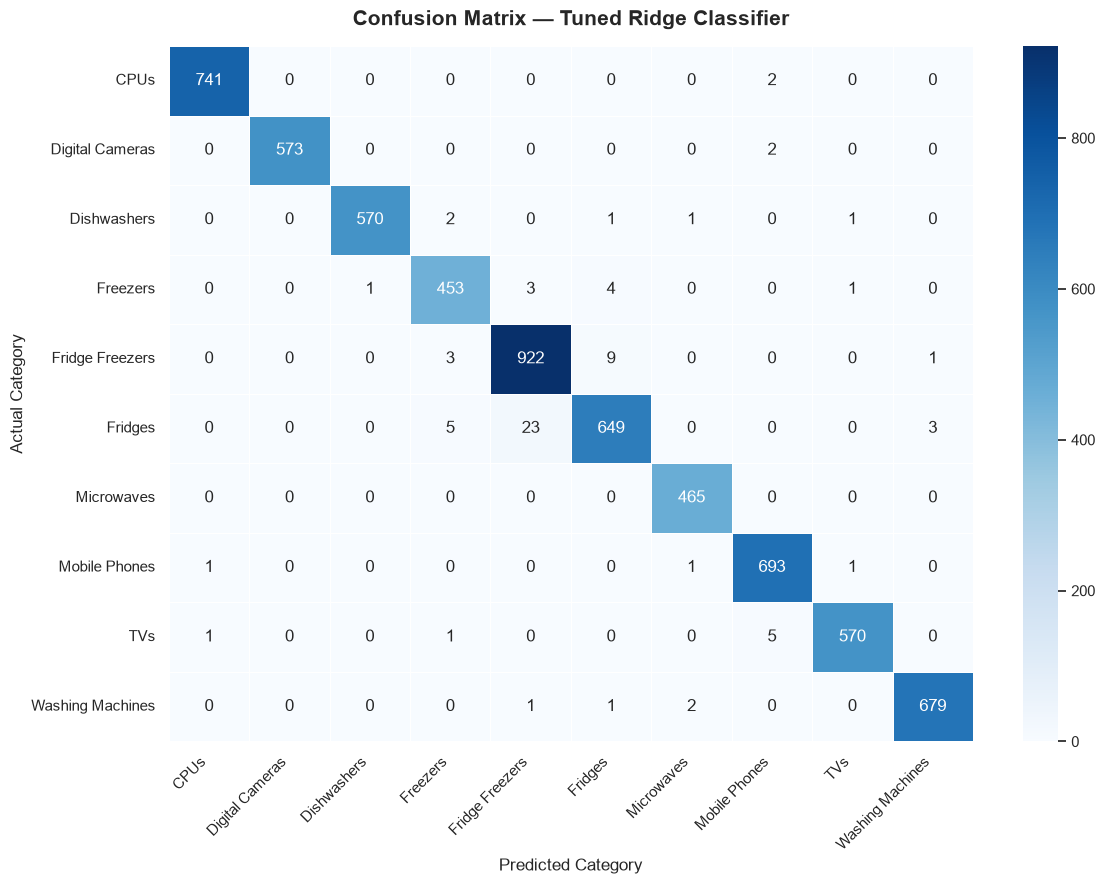

In [9]:
# Calculating the confusion matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_labels
)

# Creating the visualization
fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=category_names,
    yticklabels=category_names,
    linewidths=0.5,
    linecolor="white",
    ax=ax
)

ax.set_title(
    "Confusion Matrix — Tuned Ridge Classifier",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Predicted Category", fontsize=12)
ax.set_ylabel("Actual Category", fontsize=12)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

#### Analyzing Category-Level Misclassifications

In [10]:
# Calculating overall prediction counts
correct_predictions = np.trace(cm)
incorrect_predictions = cm.sum() - correct_predictions

print("Overall Classification Summary")
print("-" * 45)

print(f"Total Test Samples: {cm.sum():,}")
print(f"Correct Predictions: {correct_predictions:,}")
print(f"Incorrect Predictions: {incorrect_predictions:,}")
print(f"Error Rate: {incorrect_predictions / cm.sum():.2%}")

# Extracting off-diagonal misclassifications
misclassification_records = []

for actual_idx, actual_category in enumerate(category_names):

    for predicted_idx, predicted_category in enumerate(category_names):

        if actual_idx != predicted_idx:

            count = cm[actual_idx, predicted_idx]

            if count > 0:

                misclassification_records.append({
                    "Actual_Category": actual_category,
                    "Predicted_Category": predicted_category,
                    "Misclassified_Count": int(count)
                })

# Creating misclassification summary
misclassification_df = pd.DataFrame(
    misclassification_records
)

misclassification_df = (
    misclassification_df
    .sort_values(
        "Misclassified_Count",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nTop 10 Misclassification Patterns:")
display(misclassification_df.head(10))

print("\nMisclassification analysis completed successfully.")

Overall Classification Summary
---------------------------------------------
Total Test Samples: 6,391
Correct Predictions: 6,315
Incorrect Predictions: 76
Error Rate: 1.19%

Top 10 Misclassification Patterns:


,Actual_Category,Predicted_Category,Misclassified_Count
0,Fridges,Fridge Freezers,23
1,Fridge Freezers,Fridges,9
2,Fridges,Freezers,5
3,TVs,Mobile Phones,5
4,Freezers,Fridges,4
5,Freezers,Fridge Freezers,3
6,Fridges,Washing Machines,3
7,Fridge Freezers,Freezers,3
8,CPUs,Mobile Phones,2
9,Dishwashers,Freezers,2



Misclassification analysis completed successfully.


**Observations on Category-Level Misclassifications:**

- The model correctly classified **6,315 of 6,391 test samples**, producing only **76 misclassifications (1.19% error rate)**.
- The most frequent error involved **Fridges being classified as Fridge Freezers (23 cases)**, followed by Fridge Freezers being classified as Fridges (9 cases).
- Misclassifications were concentrated among refrigeration-related categories, suggesting that overlapping product terminology is a primary source of classification difficulty.

#### Examining Misclassified Product Titles

In [11]:
# Identifying incorrectly classified samples
misclassified_mask = y_test != y_test_pred

# Extracting misclassified product records
misclassified_samples_df = test_df.loc[
    misclassified_mask,
    ["Product_Title"]
].copy()

# Adding actual and predicted categories
misclassified_samples_df["Actual_Category"] = (
    label_encoder.inverse_transform(
        y_test[misclassified_mask]
    )
)

misclassified_samples_df["Predicted_Category"] = (
    label_encoder.inverse_transform(
        y_test_pred[misclassified_mask]
    )
)

# Resetting the index
misclassified_samples_df = (
    misclassified_samples_df.reset_index(drop=True)
)

# Displaying misclassified examples
print(
    f"Total Misclassified Samples: "
    f"{len(misclassified_samples_df):,}"
)

print("\nSample Misclassified Product Titles:")

display(
    misclassified_samples_df.head(20)
)

print("\nMisclassified product titles extracted successfully.")

Total Misclassified Samples: 76

Sample Misclassified Product Titles:


,Product_Title,Actual_Category,Predicted_Category
0,android 4.4.4 802.11 a/b/g/n 1d/2d imager hi2d...,Mobile Phones,CPUs
1,bullitt land rover explore,Mobile Phones,TVs
2,samsung s8500 wave sim free,Mobile Phones,Microwaves
3,silicon power computer communications inc sili...,TVs,Mobile Phones
4,xoro xor400494 htc 1946 black,TVs,Mobile Phones
5,2 power 2p 5d10k35945 notebook spare part display,TVs,CPUs
6,sony pt 1185 ir10 android windows 10 education...,TVs,Mobile Phones
7,konftel 55/55w deskphone adapter,TVs,Mobile Phones
8,sony klv 15sr1s klv15sr1s silver opened box,TVs,Mobile Phones
9,f plug cable diameter 6 mm,TVs,Freezers



Misclassified product titles extracted successfully.


**Observations on Misclassified Product Titles:**

- Several misclassified titles contain **short descriptions, model identifiers, or limited category-specific terminology**, making accurate classification more challenging.
- Errors involving TVs, Mobile Phones, and CPUs suggest that overlapping brand names, technical specifications, and accessory-related terms can introduce ambiguity.
- Some product titles appear inconsistent with their assigned categories, indicating potential dataset labeling issues that require further verification.

#### Analyzing Misclassification Patterns by Product Title Length

In [12]:
# Preparing test prediction analysis
prediction_analysis_df = test_df[
    ["Product_Title"]
].copy()

# Adding prediction correctness
prediction_analysis_df["Correct_Prediction"] = (
    y_test == y_test_pred
)

# Calculating text characteristics
prediction_analysis_df["Title_Length"] = (
    prediction_analysis_df["Product_Title"]
    .astype(str)
    .str.len()
)

prediction_analysis_df["Word_Count"] = (
    prediction_analysis_df["Product_Title"]
    .astype(str)
    .str.split()
    .str.len()
)

# Summarizing correct and incorrect predictions
title_length_summary_df = (
    prediction_analysis_df
    .groupby("Correct_Prediction")
    .agg(
        Sample_Count=("Product_Title", "size"),
        Mean_Title_Length=("Title_Length", "mean"),
        Median_Title_Length=("Title_Length", "median"),
        Mean_Word_Count=("Word_Count", "mean"),
        Median_Word_Count=("Word_Count", "median")
    )
    .reset_index()
)

# Adding readable prediction labels
title_length_summary_df["Prediction_Status"] = (
    title_length_summary_df["Correct_Prediction"]
    .map({
        True: "Correct",
        False: "Incorrect"
    })
)

# Reordering columns
title_length_summary_df = title_length_summary_df[
    [
        "Prediction_Status",
        "Sample_Count",
        "Mean_Title_Length",
        "Median_Title_Length",
        "Mean_Word_Count",
        "Median_Word_Count"
    ]
]

print("Product Title Length Analysis:")
display(title_length_summary_df.round(2))

print("\nTitle length analysis completed successfully.")

Product Title Length Analysis:


,Prediction_Status,Sample_Count,Mean_Title_Length,Median_Title_Length,Mean_Word_Count,Median_Word_Count
0,Incorrect,76,44.8400,39.5000,6.7900,6.5000
1,Correct,6315,52.8200,51.0000,8.6500,8.0000



Title length analysis completed successfully.


**Observations on Product Title Length:**

- Misclassified products had a lower average title length (**44.84 characters**) compared with correctly classified products (**52.82 characters**).
- Incorrectly classified titles contained fewer words on average (**6.79**) than correctly classified titles (**8.65**), suggesting that limited textual information may contribute to classification difficulty.
- These findings indicate an association between shorter product descriptions and classification errors, although category overlap and ambiguous terminology may also influence performance.

#### Analyzing Classification Error Rates by Title Length

Classification Error Rates by Title Length:


,Title_Length_Group,Total_Samples,Correct_Predictions,Incorrect_Predictions,Error_Rate_Pct
0,1–20,380,368,12,3.1600
1,21–40,1468,1439,29,1.9800
2,41–60,2438,2423,15,0.6200
3,61–80,1563,1549,14,0.9000
4,81+,542,536,6,1.1100


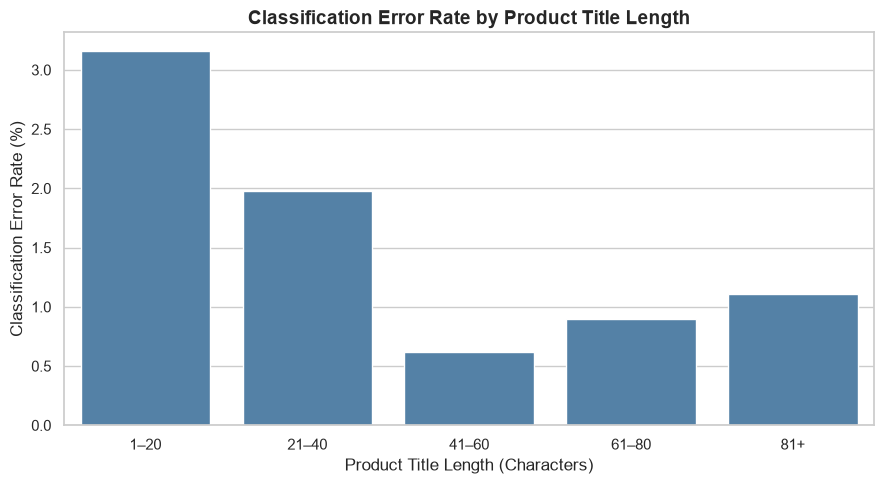

In [13]:
# Defining title-length ranges
title_length_bins = [0, 20, 40, 60, 80, np.inf]

title_length_labels = [
    "1–20",
    "21–40",
    "41–60",
    "61–80",
    "81+"
]

# Categorizing product titles by character length
prediction_analysis_df["Title_Length_Group"] = pd.cut(
    prediction_analysis_df["Title_Length"],
    bins=title_length_bins,
    labels=title_length_labels,
    include_lowest=True
)

# Calculating classification performance by title length
title_length_error_df = (
    prediction_analysis_df
    .groupby(
        "Title_Length_Group",
        observed=True
    )
    .agg(
        Total_Samples=("Correct_Prediction", "size"),
        Correct_Predictions=("Correct_Prediction", "sum")
    )
    .reset_index()
)

# Calculating incorrect predictions and error rates
title_length_error_df["Incorrect_Predictions"] = (
    title_length_error_df["Total_Samples"]
    - title_length_error_df["Correct_Predictions"]
)

title_length_error_df["Error_Rate_Pct"] = (
    title_length_error_df["Incorrect_Predictions"]
    / title_length_error_df["Total_Samples"]
    * 100
)

print("Classification Error Rates by Title Length:")
display(title_length_error_df.round(2))

# Visualizing error rates
plt.figure(figsize=(9, 5))

sns.barplot(
    data=title_length_error_df,
    x="Title_Length_Group",
    y="Error_Rate_Pct",
    color="steelblue"
)

plt.title(
    "Classification Error Rate by Product Title Length",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Product Title Length (Characters)")
plt.ylabel("Classification Error Rate (%)")

plt.tight_layout()
plt.show()

**Observations on Classification Error Rates by Title Length:**

- Titles containing **1–20 characters** recorded the highest error rate (**3.16%**), followed by titles containing 21–40 characters (**1.98%**).
- Titles containing **41–60 characters** achieved the lowest error rate (**0.62%**), suggesting that moderately detailed product descriptions provide useful classification information.
- Error rates increased slightly for longer titles, indicating that title length alone does not determine classification accuracy.